# Problem Framing
I predict squared-log-return of bitcoin, and horizon of forecasting is 7 days.

It is used to estimate the volatility when adding Bitcoin to a portfolio, and to facilitate appropriate risk management.

Consider a scenario where, at the end of each day, once the day’s market data is available, I forecast volatility for the period spanning one to seven days ahead, and estimate the variance of returns in order to optimize a portfolio which include bitcoin.
# Data exploration

In [240]:
# Import modules
from sklearn.metrics import mean_squared_error
import sys
from pathlib import Path
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.tsa.stattools import adfuller, kpss
from scipy.stats import t
from arch import arch_model
from xgboost import XGBRegressor

In [241]:
# Data Load

support_dir = Path.cwd().parent.joinpath("capstone_support")

sys.path.append(str(support_dir))

from capstone_data import load_dataset, chronological_split

df = load_dataset("bitcoin")

train, validation, test = chronological_split(df)

print(df.attrs["capstone"]["preparation"])
print(train.shape, validation.shape, test.shape)

Daily adjusted OHLC; explicit auto_adjust=True; natural-log close-to-close return and its square. First return is missing. No rolling target or future-return features precomputed. Bitcoin horizons count calendar days.
(1096, 7) (365, 7) (366, 7)


In [242]:
# Omit the first row of train data because the return of first date is NA

train = train[1:]

Text(0.5, 1.0, 'Exclude period including outliers')

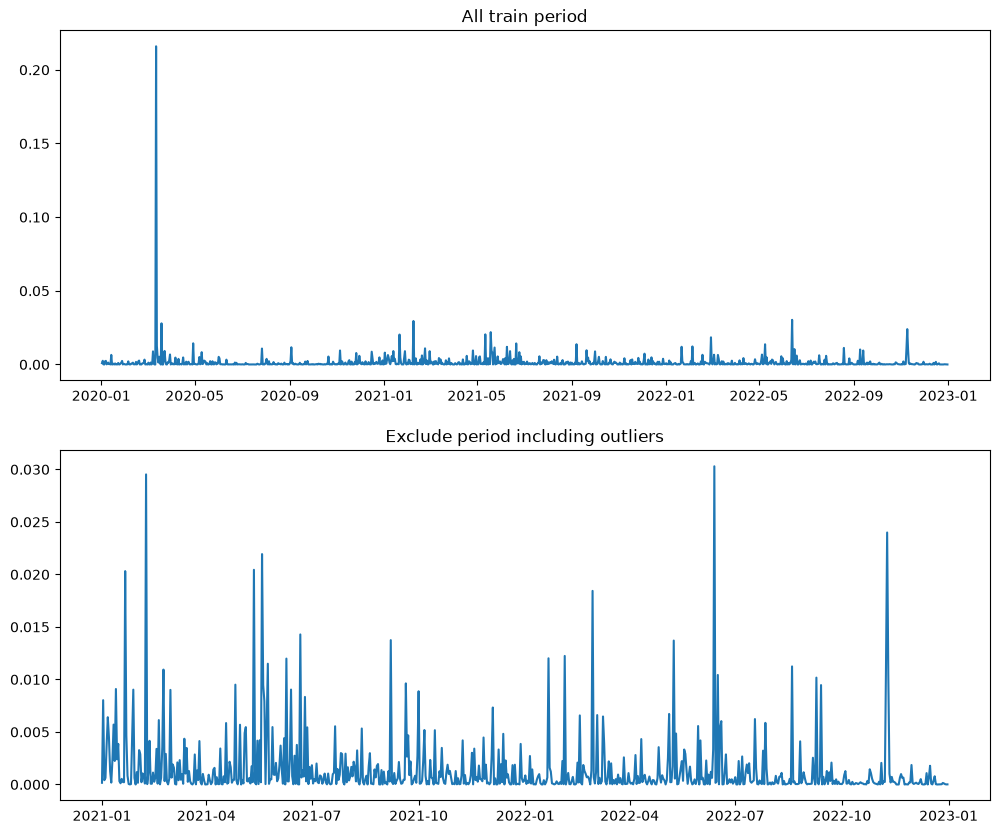

In [243]:
# Plot squared_log_return

fig, ax = plt.subplots(2, 1, figsize = (12, 10))

ax[0].plot(train["squared_log_return"])

ax[0].set_title("All train period")

ax[1].plot(train["squared_log_return"]["2021-01-01":"2022-12-31"])

ax[1].set_title("Exclude period including outliers")

Looking at the two graphs, it appears that the squared log returns of Bitcoin form clusters with some periods exhibiting high variance and others showing lower variance.

Text(0.5, 1.0, 'Exclude period including outliers')

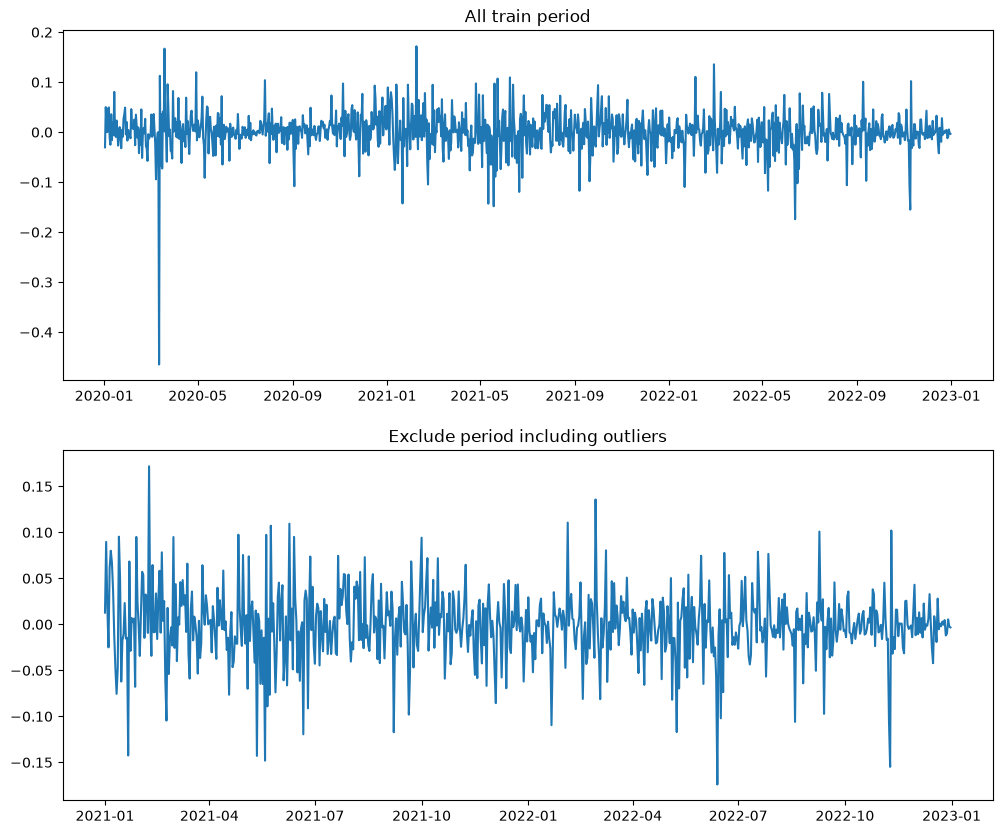

In [244]:
# Plot log_return

fig, ax = plt.subplots(2, 1, figsize = (12, 10))

ax[0].plot(train["log_return"])

ax[0].set_title("All train period")

ax[1].plot(train["log_return"]["2021-01-01":"2022-12-31"])

ax[1].set_title("Exclude period including outliers")

The log_return of bitcoin looks like stationary. 

I will statistically verified stationarity later using the ADF test and the KPSS test.

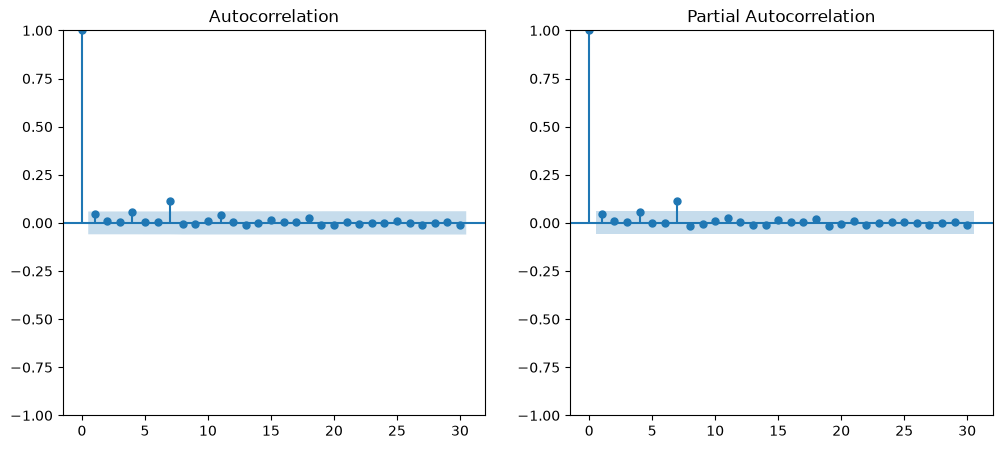

LM-test 1th p-value: 0.107257940257096
LM-test 2th p-value: 0.26400688529769967
LM-test 3th p-value: 0.4444031704045025
LM-test 4th p-value: 0.17641210007022648
LM-test 5th p-value: 0.2763521513495508
LM-test 6th p-value: 0.3891348659366281
LM-test 7th p-value: 0.0054099797537729925
LM-test 8th p-value: 0.008884046707039205
LM-test 9th p-value: 0.015502133923190647
LM-test 10th p-value: 0.025078703642482453


c:\Users\taku\Documents\Graduation_Course\MATH546_Intro_timeseries_and_forecasting\Capstone\MATH546_Capstone\venv_capstone\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [245]:
demeaned = train["log_return"] - train["log_return"].mean()

fig, axes = plt.subplots(1, 2, figsize = (12, 5))

plot_acf(demeaned**2, lags = 30, ax = axes[0])
plot_pacf(demeaned**2, lags = 30, ax = axes[1])

plt.show()


test_lags = range(1,11)
for test_n in test_lags:
    lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(demeaned, nlags = test_n)

    print(f"LM-test {test_n}th p-value: {lm_pvalue}")

There is significant autocorrelation at lag 7 in ACF and PACF.
In addition, since there are no spikes at lags 14 or 21 in the ACF, and no signs of decay in the PACF, I conclude that there is no seasonality and proceed with the analysis.

In [246]:
lags_to_test = [5,7,10,20]
lb = acorr_ljungbox(demeaned, lags=lags_to_test, return_df=True)
lb_2 = acorr_ljungbox(demeaned**2, lags=lags_to_test, return_df=True)
print(lb.to_string())
print(lb_2.to_string())

      lb_stat  lb_pvalue
5   14.422539   0.013137
7   18.752112   0.009000
10  24.014047   0.007563
20  33.987067   0.026212
      lb_stat  lb_pvalue
5    6.521861   0.258696
7   20.529678   0.004532
10  20.621567   0.023893
20  23.975895   0.243447


L-jung box test suggests that there is a autocorrelation in both log_return and squared_log_return.

In this capstone, I want to predict the the squared return of bitcoin return, so I select ARCH/GARCH model from classical statistical models.

# Model Explanation
While I will examine the extensibility of the model later, for now, I will explain the model assuming the use of GARCH(1,1).

let log_return $r_t$,
$$
\begin{aligned}
r_t &= \mu + \epsilon_t\\
\epsilon_t &= \sigma_t z_t\\
\sigma_t^2 &= \omega + \alpha \epsilon_{t-1}^2 + \beta \sigma_{t-1}^2\\
h_j &= E_T(\sigma^2_{T + j}) = Var(\epsilon_{T + j}|F_T)
\end{aligned}
$$
$z_t$ are shocks which are iid with mean zero and variance one, independent of past information.

$\mu$ is conditional mean of $r_t$, predicts the center.

$\sigma^2_t$ represents dispersion about the center.

I predict $h_j$ from ARCH/GARCH model, and predict squared_log_return

$$
\begin{aligned}
E[r_{t+j}^2|F_{t}] &= E[\mu^2|F_{t}] + 2 E[\mu \epsilon_{t+j}|F_{t}] + E[\epsilon_{t+j}^2|F_{t}]\\
&= \mu^2 + 2 \mu \sigma_{t+j} E[z_{t+j}|F_{t-1}] + h_j\\
&= \mu^2 + h_j
\end{aligned}
$$

# Check the stationary of log_return

In [247]:
adf_result = adfuller(train["log_return"], autolag = "AIC")
adf_stat = adf_result[0]
adf_pval = adf_result[1]

kpss_result = kpss(train["log_return"], regression="c", nlags="auto")
kpss_stat = kpss_result[0]
kpss_pval = kpss_result[1]

print(f"ADF Statistic: {adf_stat}")
print(f"ADF p-value: {adf_pval}")
print(f"KPSS Statistic: {kpss_stat}")
print(f"KPSS p-value: {kpss_pval}")

ADF Statistic: -10.669771471335435
ADF p-value: 4.196297345647625e-19
KPSS Statistic: 0.5671735301458307
KPSS p-value: 0.02653749321039848


C:\Users\taku\AppData\Local\Temp\ipykernel_23316\2454384448.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train["log_return"], autolag = "AIC")
C:\Users\taku\AppData\Local\Temp\ipykernel_23316\2454384448.py:5: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(train["log_return"], regression=

The results of the ADF test led to the rejection of the null hypothesis that log_return is a non-stationary process, while the results of the KPSS test led to the rejection of the null hypothesis that log_return is a stationary process.

These results suggest that the stationarity of Bitcoin log returns is not clear.

To ensure robustness, we examine the ACF and PACF of the series after taking a first-order difference.

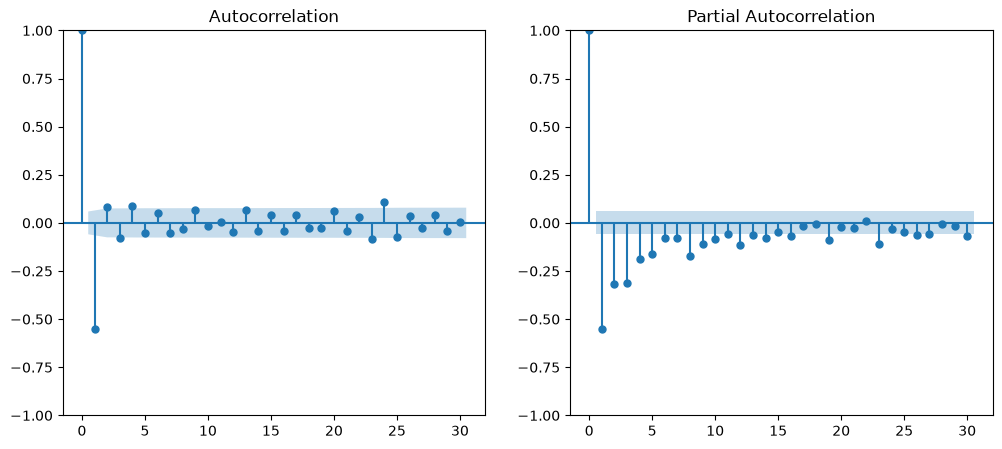

In [248]:
diff = train["log_return"].diff()[1:]
fig, axes = plt.subplots(1, 2, figsize = (12, 5))

plot_acf(diff, lags = 30, ax = axes[0])
plot_pacf(diff, lags = 30, ax = axes[1])

plt.show()

An examination of the ACF and PACF plots for the first differenced log returns shows a significant negative autocorrelation at lag 1 in the ACF, along with a decaying pattern of negative autocorrelation in the PACF. These results suggest that the data has been over differenced.

Although the ADF test rejects the unit-root hypothesis, the KPSS test also rejects the stationarity hypothesis. These conflicting results suggest possible instability in the log return series. Nevertheless, I proceed with the GARCH analysis while acknowledging this limitation.

In [249]:
# Compare ARCH GARCH t-GARCH

model_arch = arch_model(train["log_return"], vol = "Arch", p = 7, rescale=False)
model_garch = arch_model(train["log_return"], vol = "Garch", p = 1, q = 1, rescale=False)
model_tgarch = arch_model(train["log_return"], vol = "Garch", p = 1, q = 1, dist = "studentst", rescale=False)

arch_result = model_arch.fit(disp = "off")
garch_result = model_garch.fit(disp = "off")
tgarch_result = model_tgarch.fit(disp = "off")

print(arch_result.summary())

                      Constant Mean - ARCH Model Results                      
Dep. Variable:             log_return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                       ARCH   Log-Likelihood:                2072.57
Distribution:                  Normal   AIC:                          -4127.15
Method:            Maximum Likelihood   BIC:                          -4082.16
                                        No. Observations:                 1095
Date:                Mon, Nov 09 2026   Df Residuals:                     1094
Time:                        17:15:29   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         1.6096e-03  1.148e-03      1.402      0.161 

In [250]:
print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:             log_return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                2030.86
Distribution:                  Normal   AIC:                          -4053.72
Method:            Maximum Likelihood   BIC:                          -4033.73
                                        No. Observations:                 1095
Date:                Mon, Nov 09 2026   Df Residuals:                     1094
Time:                        17:15:29   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         1.9667e-03  1.291e-03      1.523      0.128 

In [251]:
print(tgarch_result.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   log_return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:                2169.70
Distribution:      Standardized Student's t   AIC:                          -4329.41
Method:                  Maximum Likelihood   BIC:                          -4304.41
                                              No. Observations:                 1095
Date:                      Mon, Nov 09 2026   Df Residuals:                     1094
Time:                              17:15:29   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
m

In [252]:
# summarize the result
result_table = pd.DataFrame(columns=["Model", "AIC", "BIC", "Convergence"])
result_table["Model"] = ["ARCH(7)", "GARCH(1,1)", "Student-t GARCH"]
result_table["AIC"] = [arch_result.aic, garch_result.aic, tgarch_result.aic]
result_table["BIC"] = [arch_result.bic, garch_result.bic, tgarch_result.bic]
result_table["Convergence"] = [arch_result.convergence_flag == 0,
                               garch_result.convergence_flag == 0,
                               tgarch_result.convergence_flag == 0]

result_table

,Model,AIC,BIC,Convergence
0,ARCH(7),-4127.148330,-4082.161743,True
1,"GARCH(1,1)",-4053.719442,-4033.725403,True
2,Student-t GARCH,-4329.406566,-4304.414018,True


The Student-t GARCH model yield the best results among the three models in terms of both AIC and BIC.

And the estimate of all three model is converged, so I choose t-GARCH(1,1) based on BIC.

In [253]:
# Check the stationarity of unconditional variance
rho = tgarch_result.params["alpha[1]"] + tgarch_result.params["beta[1]"]
v = tgarch_result.params["omega"] / (1 - rho)

print(f"The persistence of variance: {rho:.4f}")
print(f"long-run variance: {v:.4f}")

The persistence of variance: 0.9000
long-run variance: 0.0015


The estimated persistence is about 0.9, and the implied long-run variance is 0.0015

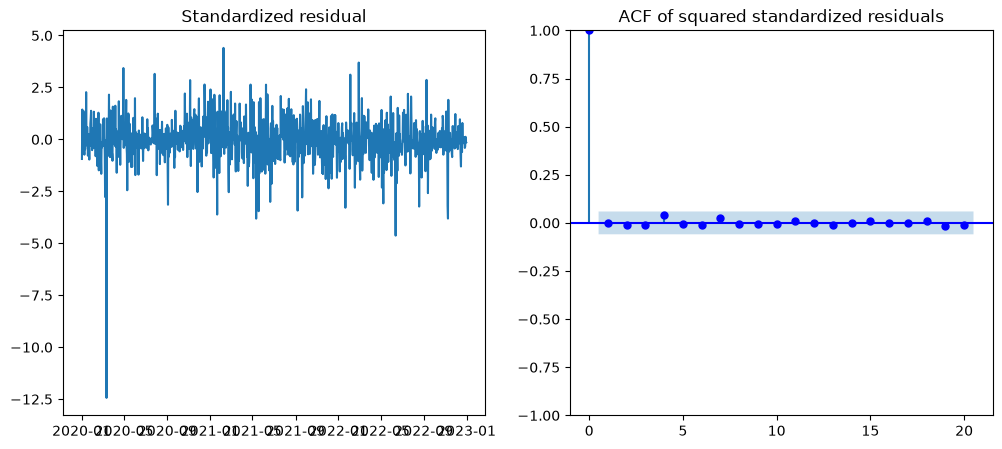

In [254]:
# Check Residual

resid = tgarch_result.std_resid

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(resid)
axes[0].set_title("Standardized residual")
plot_acf(resid**2, ax = axes[1], lags = 20, color = "blue")
axes[1].set_title("ACF of squared standardized residuals")

plt.show()

there is no autocorrelation in the residual of t-GARCH(1,1), so the model was able to capture the structure of the time-series data to some extent.

However, there is a outlier in standardized residual and it can not be captured in this model.

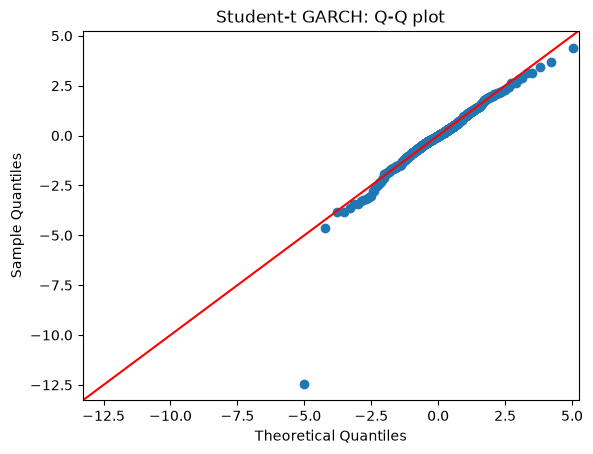

In [255]:
nu = tgarch_result.params["nu"]

sm.qqplot(
    resid,
    dist=t,
    distargs=(nu,),
    scale = np.sqrt((nu-2) / nu),
    line="45"
)

plt.title("Student-t GARCH: Q-Q plot")

plt.show()

An examination of the residual distribution reveals slight deviations from a Student-t distribution in the tails, as well as a failure to fully capture outliers. However, the residuals generally follow a Student-t distribution.

# Rolling 7-days Forecast of t-GARCH

In [256]:
omega = tgarch_result.params["omega"]
alpha = tgarch_result.params["alpha[1]"]
beta  = tgarch_result.params["beta[1]"]
mu = tgarch_result.params["mu"]

rho = alpha + beta
h = pd.Series()

# Set the last resid and variance
last_resid = tgarch_result.resid.iloc[-1]
last_var   = tgarch_result.conditional_volatility.iloc[-1] ** 2

# Set the dataframe for calculate rolling RMSE
# The indexs represents the date of the final data point used for the estimation.
# The columns represents the forecast of variance in n-th days future.

TG_rolling_forecast = pd.DataFrame(index = validation.index - pd.Timedelta(days = 1),
                                columns=[f"target_{i}" for i in range(1, 8)])

for date in range(0, len(validation) - 6):

    # first-step forecast
    h = omega + alpha * last_resid**2 + beta * last_var

    predicted_var = [h]

    # 2-7 days forecast
    for n in range(1, 7):
        h = omega + rho * h
        predicted_var.append(h)

    # Transfer from expected conditional variance to expected squared_log_return
    predicted_squared_return = predicted_var + mu**2

    for horizon in range(0, 7):
        TG_rolling_forecast.iloc[date, horizon] = predicted_squared_return[horizon]

    # update the last resid and variance
    last_resid = validation["log_return"].iloc[date] - mu
    last_var = predicted_var[0]

# Omit first forecast (use information until 2022-12-31 to predict from 2023-01-01) to compare Random Forest
TG_rolling_forecast = TG_rolling_forecast[1:]

# Omit last 6 days forecast because the prediction period overlaps with the test period.
TG_rolling_forecast = TG_rolling_forecast[0:-6]

# transfer dataframe to long dataframe to calculate RMSE
TG_rolling_forecast = pd.melt(
    TG_rolling_forecast,
    value_vars=[f"target_{h}" for h in range(1, 8)],
    var_name="target_horizon",
    value_name="Forecast",
    ignore_index=False
)

TG_rolling_forecast["target_horizon"] = TG_rolling_forecast["target_horizon"].str.replace("target_", "", regex=False).astype(int)

for date in validation[0:-7].index:
    for horizon in range(1, 8):
        TG_rolling_forecast.loc[(TG_rolling_forecast.index == date) & (TG_rolling_forecast["target_horizon"] == horizon), "Actual"] = validation.shift(-horizon).loc[date, "squared_log_return"]

tGARCH_RMSE = np.sqrt(mean_squared_error(TG_rolling_forecast["Forecast"], TG_rolling_forecast["Actual"]))

In [257]:
print(f"The number of predictions (Forecast period * 7 days): {len(TG_rolling_forecast)}")
print(f"Forecast start date: {TG_rolling_forecast.index[0]}")
print(f"Forecast end date: {TG_rolling_forecast.index[-1]}")

The number of predictions (Forecast period * 7 days): 2506
Forecast start date: 2023-01-01 00:00:00
Forecast end date: 2023-12-24 00:00:00


# Model 2 (Tree-Based ML)

In addition, I choose Tree-Based ML Model to estimate the volatility of Bitcoin return because

1. The train data is 1095 and is not so much to use Neural-network model.
2. Tree-Based ML Model can capture non-linear structures, it may also be effective for addressing outliers that t-GARCH fails to adequately account for.
3. Tree-Based ML Model can output how much the explanatory variable contribute to the estimate, which is useful when I report the predict of bitcoin volatility because I can explain what factor may contribute the volatility of bitcoin.

As explanatory variables, I add the previous day’s value of log_squared_return, which represent short-term variance, a one-week average, which represent medium-term variance, and a one-month average, which represent long-term variance.

In [258]:
# Create data table with additional 
n_lag = 7

ex_var = ["Close", "High", "Low", "Open", "Volume"]

train_rf = train.copy()
validation_rf = validation.copy()

# Make train + validation dataframe to make moving averages in validation period
df_join = pd.concat([train_rf, validation_rf])

# add moving average of variance
for i in range(0, n_lag):
    train_rf[f"lag_{i}"] = train_rf["squared_log_return"].shift(i)
    validation_rf[f"lag_{i}"] = validation_rf["squared_log_return"].shift(i)

# Add lagged squared_log_return from training data
for i in range(0, 6):
    for j in range(i + 1, 7):
        validation_rf.loc[validation_rf.index[i], f"lag_{j}"] = train_rf["squared_log_return"].iloc[-j + i]

# add moving average of variance
train_rf["mv_7"] = train_rf["squared_log_return"].rolling(7).mean()
validation_rf["mv_7"] = df_join["squared_log_return"].rolling(7).mean().loc[validation_rf.index]

train_rf["mv_30"] = train_rf["squared_log_return"].rolling(30).mean()
validation_rf["mv_30"] = df_join["squared_log_return"].rolling(30).mean().loc[validation_rf.index]

train_rf["Range"] = np.log(train_rf["High"]/train_rf["Low"])
validation_rf["Range"] = np.log(validation_rf["High"]/validation_rf["Low"])

# add future return to predict 7-days horizon forecast
for h in range(1, 8):
    train_rf[f"target_{h}"] = train_rf["squared_log_return"].shift(-h)
    validation_rf[f"target_{h}"] = validation_rf["squared_log_return"].shift(-h)

# Drop last 7 days in train data because the forecast period overlaps with the validation period.
train_rf = train_rf[0:-7]

# Drop first 29 days in train data because 30-days moving average cannnot be calculated.
train_rf = train_rf[29:]

# Drop last 7 days in validation data because the forecast period overlaps with the test period.
validation_rf = validation_rf[0:-7]

# Transfer long dataframe to add explanatory variable of forecast horizon period
df_long = pd.melt(
    train_rf,
    id_vars=["lag_0", "lag_1", "lag_2", "lag_3", "lag_4", "lag_5", "lag_6", "mv_7", "mv_30", "Volume", "Range"],
    value_vars=[f"target_{h}" for h in range(1, 8)],
    var_name="target_horizon",
    value_name="Forecast"
)

df_long["target_horizon"] = df_long["target_horizon"].str.replace("target_", "", regex=False).astype(int)

# Fit Random Forest
feature_cols = ["lag_0", "lag_1", "lag_2", "lag_3", "lag_4", "lag_5", "lag_6", "mv_7", "mv_30", "Volume", "Range", "target_horizon"]

rf = XGBRegressor(
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)

rf.fit(df_long[feature_cols], df_long["Forecast"])

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [259]:
validation_long = pd.melt(
    validation_rf,
    id_vars=["lag_0", "lag_1", "lag_2", "lag_3", "lag_4", "lag_5", "lag_6", "mv_7", "mv_30", "Volume", "Range"],
    value_vars=[f"target_{h}" for h in range(1, 8)],
    var_name="target_horizon",
    value_name="Forecast",
    ignore_index=False
)

validation_long["target_horizon"] = validation_long["target_horizon"].str.replace("target_", "", regex=False).astype(int)

RF_rolling_forecast = pd.DataFrame(index = validation_long.index,
                                   columns=["Actual","Forecast","target_horizon"])


predicted_squared_return = rf.predict(validation_long[feature_cols])
actual_var = validation_long["Forecast"]

XGB_rmse = np.sqrt(mean_squared_error(actual_var, predicted_squared_return))

RF_rolling_forecast["Actual"] = actual_var
RF_rolling_forecast["Forecast"] = predicted_squared_return
RF_rolling_forecast["target_horizon"] = validation_long["target_horizon"]
RF_rolling_forecast.index = validation_long.index

In [260]:
print(f"The number of predictions (Forecast period * 7 days): {len(RF_rolling_forecast)}")
print(f"Forecast start date: {RF_rolling_forecast.index[0]}")
print(f"Forecast end date: {RF_rolling_forecast.index[-1]}")

The number of predictions (Forecast period * 7 days): 2506
Forecast start date: 2023-01-01 00:00:00
Forecast end date: 2023-12-24 00:00:00


In [261]:
importance = pd.Series(
    rf.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

print(importance)

lag_0             0.364829
Volume            0.104633
mv_7              0.103302
lag_2             0.092902
lag_4             0.076507
Range             0.058121
mv_30             0.057048
lag_1             0.050481
lag_6             0.035007
lag_5             0.023790
lag_3             0.022934
target_horizon    0.010447
dtype: float32


Based on the features used in the XGBoost model, the previous day’s squared return, trading volume, and the 7-day moving average of squared returns contribute to the prediction of future squared returns.

# Model 3 (Naive Forecast)
Finally, I select naive forecast based on the previous day's value (Persistence Naive).

In [262]:
NB_rolling_forecast = pd.DataFrame(index = validation.index,
                                columns=[f"target_{i}" for i in range(1, 8)])

# Make train + validation dataframe to calculate first baseline forecast in validation period.

df_naive = pd.concat([train, validation])

for date in range(0, len(validation)):
    for horizon in range(0, 7):
        naive_predict = df_naive["squared_log_return"].iloc[len(train) + date]
        NB_rolling_forecast.iloc[date, horizon] = naive_predict

NB_rolling_forecast.dropna(inplace=True)

# transfer dataframe to long dataframe to calculate RMSE
NB_rolling_forecast = pd.melt(
    NB_rolling_forecast,
    value_vars=[f"target_{h}" for h in range(1, 8)],
    var_name="target_horizon",
    value_name="Forecast",
    ignore_index=False
)

NB_rolling_forecast["target_horizon"] = NB_rolling_forecast["target_horizon"].str.replace("target_", "", regex=False).astype(int)

for date in validation[0:-7].index:
   for horizon in range(1, 8):
       NB_rolling_forecast.loc[(NB_rolling_forecast.index == date) & (NB_rolling_forecast["target_horizon"] == horizon), "Actual"] = validation.shift(-horizon).loc[date, "squared_log_return"]

NB_rolling_forecast.dropna(inplace=True)

NB_RMSE = np.sqrt(mean_squared_error(NB_rolling_forecast["Forecast"], NB_rolling_forecast["Actual"]))

In [263]:
print(f"The number of predictions (Forecast period * 7 days): {len(NB_rolling_forecast)}")
print(f"Forecast start date: {NB_rolling_forecast.index[0]}")
print(f"Forecast end date: {NB_rolling_forecast.index[-1]}")

The number of predictions (Forecast period * 7 days): 2506
Forecast start date: 2023-01-01 00:00:00
Forecast end date: 2023-12-24 00:00:00


# Compare three models

In [264]:
# summarize the result
result_table = pd.DataFrame(columns=["Model", "RMSE"])
result_table["Model"] = ["Student-t GARCH", "XGBoost", "Naive Baseline"]
result_table["RMSE"] = [tGARCH_RMSE, XGB_rmse, NB_RMSE]

result_table

,Model,RMSE
0,Student-t GARCH,0.001399
1,XGBoost,0.001396
2,Naive Baseline,0.001642


The RMSE of both Student-t GARCH and XGBoost yield better results than the baseline. 

Furthermore, the RMSE for XGBoost was slightly better than that for the Student-t GARCH, so I finally choose XGBoost Model to predict log_squared_return of bitcoin.

Although XGBoost yields the lowest RMSE during the validation period, the difference compared to the student-t GARCH model is marginal.

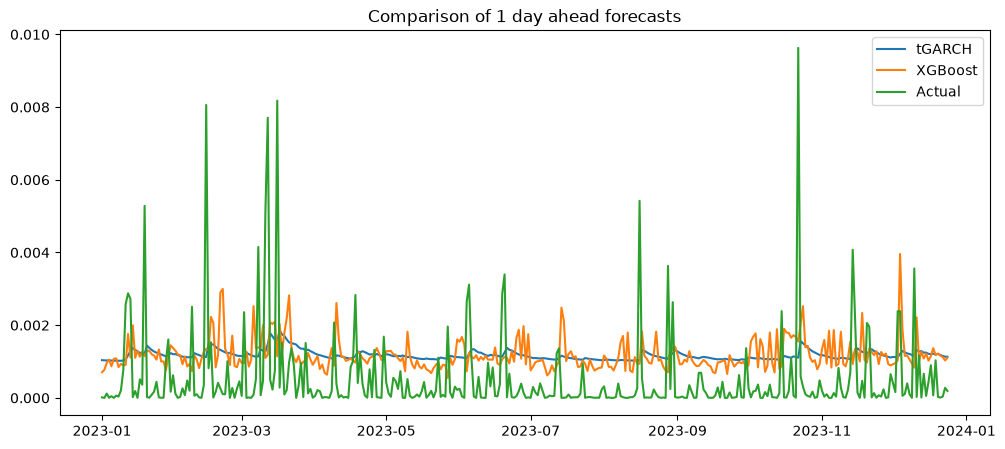

In [265]:
tGARCH_1day_forecast = TG_rolling_forecast[TG_rolling_forecast["target_horizon"] == 1]
XGB_1day_forecast = RF_rolling_forecast[RF_rolling_forecast["target_horizon"] == 1]
NB_1day_forecast = NB_rolling_forecast[NB_rolling_forecast["target_horizon"] == 1]

fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(tGARCH_1day_forecast["Forecast"], label = "tGARCH")
ax.plot(XGB_1day_forecast["Forecast"], label = "XGBoost")
ax.plot(NB_1day_forecast["Actual"], label = "Actual")

ax.set_title("Comparison of 1 day ahead forecasts")

plt.legend()
plt.show()

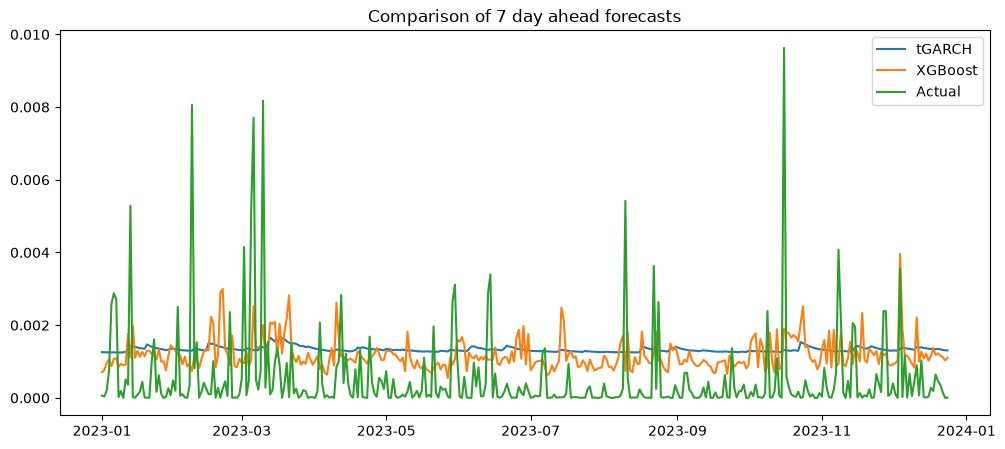

In [266]:
tGARCH_7day_forecast = TG_rolling_forecast[TG_rolling_forecast["target_horizon"] == 7]
XGB_7day_forecast = RF_rolling_forecast[RF_rolling_forecast["target_horizon"] == 7]
NB_7day_forecast = NB_rolling_forecast[NB_rolling_forecast["target_horizon"] == 7]

fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(tGARCH_7day_forecast["Forecast"], label = "tGARCH")
ax.plot(XGB_7day_forecast["Forecast"], label = "XGBoost")
ax.plot(NB_7day_forecast["Actual"], label = "Actual")

ax.set_title("Comparison of 7 day ahead forecasts")

plt.legend()
plt.show()

Comparing the 1-day-ahead and 7-day-ahead forecasts across the models, the Student-t GARCH model shows almost no deviation from its implied long-term variance, whereas the XGBoost model exhibits greater variability in its forecasts—though it does, at times, succeed in predicting significant fluctuations.

# Test Evaluation

In [267]:
# XGBoost

test_rf = test.copy()

# Make validation + test dataframe to make moving averages in test period
df_join = pd.concat([validation, test_rf])

# add moving average of variance
for i in range(0, n_lag):
    test_rf[f"lag_{i}"] = test_rf["squared_log_return"].shift(i)

# Add lagged squared_log_return in first 7 days from validation data
for i in range(0, 6):
    for j in range(i + 1, 7):
        test_rf.loc[test_rf.index[i], f"lag_{j}"] = validation["squared_log_return"].iloc[-j + i]

# add moving average of variance
test_rf["mv_7"] = df_join["squared_log_return"].rolling(7).mean().loc[test_rf.index]
test_rf["mv_30"] = df_join["squared_log_return"].rolling(30).mean().loc[test_rf.index]

test_rf["Range"] = np.log(test_rf["High"]/test_rf["Low"])

for h in range(1, 8):
    test_rf[f"target_{h}"] = test_rf["squared_log_return"].shift(-h)

test_rf.dropna(inplace = True)


test_long = pd.melt(
    test_rf,
    id_vars=["lag_0", "lag_1", "lag_2", "lag_3", "lag_4", "lag_5", "lag_6", "mv_7", "mv_30", "Volume", "Range"],
    value_vars=[f"target_{h}" for h in range(1, 8)],
    var_name="target_horizon",
    value_name="Forecast",
    ignore_index=False
)

test_long["target_horizon"] = test_long["target_horizon"].str.replace("target_", "", regex=False).astype(int)

test_rolling_forecast = pd.DataFrame(index = test_long.index,
                                   columns=["Actual","Forecast","target_horizon"])

predicted_squared_return = rf.predict(test_long[feature_cols])

actual_var = test_long["Forecast"]

test_rmse = np.sqrt(mean_squared_error(actual_var, predicted_squared_return))

test_rolling_forecast["Actual"] = actual_var
test_rolling_forecast["Forecast"] = predicted_squared_return
test_rolling_forecast["target_horizon"] = test_long["target_horizon"]
test_rolling_forecast.index = test_long.index

In [268]:
print(f"The number of predictions (Forecast period * 7 days): {len(test_rolling_forecast)}")
print(f"Forecast start date: {test_rolling_forecast.index[0]}")
print(f"Forecast end date: {test_rolling_forecast.index[-1]}")

The number of predictions (Forecast period * 7 days): 2513
Forecast start date: 2024-01-01 00:00:00
Forecast end date: 2024-12-24 00:00:00


In [269]:
# Student-t GARCH

# Initial conditional variance and residual at the end of training period
last_resid = tgarch_result.resid.iloc[-1]
last_var = tgarch_result.conditional_volatility.iloc[-1] ** 2

h = pd.Series()

# Update conditional variance and residual to forecast in test period
for date in validation.index:

    # Update conditional variance
    current_var = omega + alpha * last_resid**2 + beta * last_var

    # Update residual
    current_resid = validation.loc[date, "log_return"] - mu

    last_var = current_var
    last_resid = current_resid

TG_test_forecast = pd.DataFrame(index = test.index,
                                columns=[f"target_{i}" for i in range(1, 8)])

for date in range(0, len(test)):

    # first-step forecast
    
    # Update conditional variance
    current_var = omega + alpha * last_resid**2 + beta * last_var

    # Update residual
    current_resid = test["log_return"].iloc[date] - mu

    # Forecast 1 day ahead
    h = omega + alpha * current_resid**2 + beta * current_var

    predicted_var = [h]

    # 2-7 days forecast
    for n in range(1, 7):
        h = omega + rho * h
        predicted_var.append(h)

    # Transfer from expected conditional variance to expected squared_log_return
    predicted_squared_return = predicted_var + mu**2

    for horizon in range(0, 7):
        TG_test_forecast.iloc[date, horizon] = predicted_squared_return[horizon]

    # update the last resid and variance
    last_resid = current_resid
    last_var = current_var

# Omit last 7 days forecast because the forecast period extends beyond the test period.
TG_test_forecast = TG_test_forecast[0:-7]

# transfer dataframe to long dataframe to calculate RMSE
TG_test_forecast = pd.melt(
    TG_test_forecast,
    value_vars=[f"target_{h}" for h in range(1, 8)],
    var_name="target_horizon",
    value_name="Forecast",
    ignore_index=False
)

TG_test_forecast["target_horizon"] = TG_test_forecast["target_horizon"].str.replace("target_", "", regex=False).astype(int)

for date in test[0:-7].index:
    for horizon in range(1, 8):
        TG_test_forecast.loc[(TG_test_forecast.index == date) & (TG_test_forecast["target_horizon"] == horizon), "Actual"] = test.shift(-horizon).loc[date, "squared_log_return"]

test_tGARCH_RMSE = np.sqrt(mean_squared_error(TG_test_forecast["Forecast"], TG_test_forecast["Actual"]))

In [270]:
print(f"The number of predictions (Forecast period * 7 days): {len(TG_test_forecast)}")
print(f"Forecast start date: {TG_test_forecast.index[0]}")
print(f"Forecast end date: {TG_test_forecast.index[-1]}")

The number of predictions (Forecast period * 7 days): 2513
Forecast start date: 2024-01-01 00:00:00
Forecast end date: 2024-12-24 00:00:00


In [271]:
# Naive Baseline

NB_rolling_forecast = pd.DataFrame(index = test.index,
                                columns=[f"target_{i}" for i in range(1, 8)])

# Make validation + test dataframe to calculate first baseline forecast in test period.

df_naive = pd.concat([validation, test])

for date in range(0, len(test) - 6):
    for horizon in range(0, 7):
        naive_predict = df_naive["squared_log_return"].iloc[len(validation) + date]
        NB_rolling_forecast.iloc[date, horizon] = naive_predict

NB_rolling_forecast.dropna(inplace=True)

# transfer dataframe to long dataframe to calculate RMSE
NB_rolling_forecast = pd.melt(
    NB_rolling_forecast,
    value_vars=[f"target_{h}" for h in range(1, 8)],
    var_name="target_horizon",
    value_name="Forecast",
    ignore_index=False
)

NB_rolling_forecast["target_horizon"] = NB_rolling_forecast["target_horizon"].str.replace("target_", "", regex=False).astype(int)

for date in test[0:-7].index:
   for horizon in range(1, 8):
       NB_rolling_forecast.loc[(NB_rolling_forecast.index == date) & (NB_rolling_forecast["target_horizon"] == horizon), "Actual"] = test.shift(-horizon).loc[date, "squared_log_return"]

NB_rolling_forecast.dropna(inplace=True)

NB_RMSE = np.sqrt(mean_squared_error(NB_rolling_forecast["Forecast"], NB_rolling_forecast["Actual"]))

In [272]:
print(f"The number of predictions (Forecast period * 7 days): {len(NB_rolling_forecast)}")
print(f"Forecast start date: {NB_rolling_forecast.index[0]}")
print(f"Forecast end date: {NB_rolling_forecast.index[-1]}")

The number of predictions (Forecast period * 7 days): 2513
Forecast start date: 2024-01-01 00:00:00
Forecast end date: 2024-12-24 00:00:00


In [273]:
# summarize the result
result_table = pd.DataFrame(columns=["Model", "RMSE"])
result_table["Model"] = ["XGBoost", "Student-t GARCH", "Naive Baseline"]
result_table["RMSE"] = [test_rmse, test_tGARCH_RMSE, NB_RMSE]

result_table

,Model,RMSE
0,XGBoost,0.001724
1,Student-t GARCH,0.001614
2,Naive Baseline,0.002092


Comparing the RMSE during the test period between the selected XGBoost model and the baseline, the XGBoost model demonstrated a better score.

However, Student-t GARCH outperformed XGBoost in the test period. 

This suggests that the forecasting performance of the models may vary across the forecast period and market conditions.

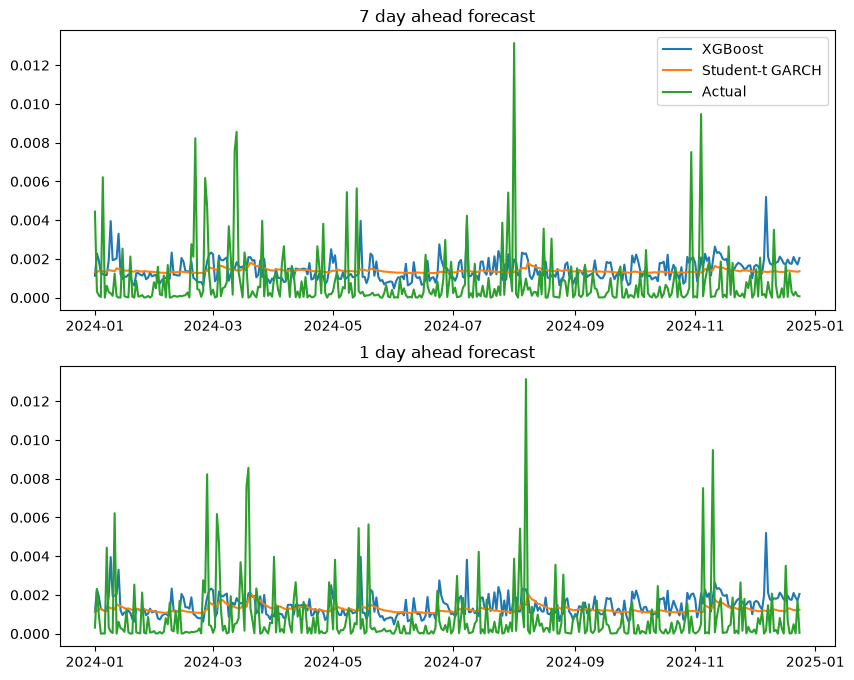

In [274]:
test_7day_forecast = test_rolling_forecast[test_rolling_forecast["target_horizon"] == 7]
TG_7day_forecast = TG_test_forecast[TG_test_forecast["target_horizon"] == 7]
NB_7day_forecast = NB_rolling_forecast[NB_rolling_forecast["target_horizon"] == 7]

test_1day_forecast = test_rolling_forecast[test_rolling_forecast["target_horizon"] == 1]
TG_1day_forecast = TG_test_forecast[TG_test_forecast["target_horizon"] == 1]
NB_1day_forecast = NB_rolling_forecast[NB_rolling_forecast["target_horizon"] == 1]

fig, ax = plt.subplots(2, 1, figsize=(10, 8))

ax[0].plot(test_7day_forecast["Forecast"], label = "XGBoost")
ax[0].plot(TG_7day_forecast["Forecast"], label = "Student-t GARCH")
ax[0].plot(NB_7day_forecast["Actual"], label = "Actual")

ax[1].plot(test_1day_forecast["Forecast"], label = "XGBoost")
ax[1].plot(TG_1day_forecast["Forecast"], label = "Student-t GARCH")
ax[1].plot(NB_1day_forecast["Actual"], label = "Actual")

ax[0].legend()

ax[0].set_title("7 day ahead forecast")
ax[1].set_title("1 day ahead forecast")
plt.show()

Comparing the predicted values ​​with the actual values ​​during the test period, there are significant spikes in the actual data which cannnot be captured in this model.

# Robustness Check

To assess robustness, I compare the RMSE for one-day-ahead forecasts with that for seven-day-ahead forecasts to determine whether the RMSE varies significantly based on the forecast horizon. Additionally, I divide the test period into two periods, an earlier and a later phase, to examine whether the RMSE differs between them.

In [282]:
XGB_one_day_forecast = test_rolling_forecast[(test_rolling_forecast["target_horizon"] == 1)]["Forecast"]
XGB_one_day_actual = test_rolling_forecast[(test_rolling_forecast["target_horizon"] == 1)]["Actual"]

TG_one_day_forecast = TG_test_forecast[(TG_test_forecast["target_horizon"] == 1)]["Forecast"]
TG_one_day_actual = TG_test_forecast[(TG_test_forecast["target_horizon"] == 1)]["Actual"]

NB_one_day_forecast = NB_rolling_forecast[(NB_rolling_forecast["target_horizon"] == 1)]["Forecast"]
NB_one_day_actual = NB_rolling_forecast[(NB_rolling_forecast["target_horizon"] == 1)]["Actual"]


XGB_seven_day_forecast = test_rolling_forecast[(test_rolling_forecast["target_horizon"] == 7)]["Forecast"]
XGB_seven_day_actual = test_rolling_forecast[(test_rolling_forecast["target_horizon"] == 7)]["Actual"]

TG_seven_day_forecast = TG_test_forecast[(TG_test_forecast["target_horizon"] == 7)]["Forecast"]
TG_seven_day_actual = TG_test_forecast[(TG_test_forecast["target_horizon"] == 7)]["Actual"]

NB_seven_day_forecast = NB_rolling_forecast[(NB_rolling_forecast["target_horizon"] == 7)]["Forecast"]
NB_seven_day_actual = NB_rolling_forecast[(NB_rolling_forecast["target_horizon"] == 7)]["Actual"]


XGB_one_day_RMSE = np.sqrt(mean_squared_error(XGB_one_day_forecast, XGB_one_day_actual))
XGB_seven_day_RMSE = np.sqrt(mean_squared_error(XGB_seven_day_forecast, XGB_seven_day_actual))

TG_one_day_RMSE = np.sqrt(mean_squared_error(TG_one_day_forecast, TG_one_day_actual))
TG_seven_day_RMSE = np.sqrt(mean_squared_error(TG_seven_day_forecast, TG_seven_day_actual))

NB_one_day_RMSE = np.sqrt(mean_squared_error(NB_one_day_forecast, NB_one_day_actual))
NB_seven_day_RMSE = np.sqrt(mean_squared_error(NB_seven_day_forecast, NB_seven_day_actual))

In [283]:
# summarize the result
result_table = pd.DataFrame(index = ["XGBoost", "Student-t GARCH", "Naive Baseline"],
                            columns = ["1 day ahead forecast", "7 day ahead forecast"])
result_table.loc["XGBoost", "1 day ahead forecast"] = XGB_one_day_RMSE
result_table.loc["XGBoost", "7 day ahead forecast"] = XGB_seven_day_RMSE
result_table.loc["Student-t GARCH", "1 day ahead forecast"] = TG_one_day_RMSE
result_table.loc["Student-t GARCH", "7 day ahead forecast"] = TG_seven_day_RMSE
result_table.loc["Naive Baseline", "1 day ahead forecast"] = NB_one_day_RMSE
result_table.loc["Naive Baseline", "7 day ahead forecast"] = NB_seven_day_RMSE

result_table

,1 day ahead forecast,7 day ahead forecast
XGBoost,0.001712,0.001716
Student-t GARCH,0.001588,0.00164
Naive Baseline,0.002063,0.002188


The RMSE of a 7-day horizon is slightly worse than that of a 1-day horizon. 

This suggests that predicting squared returns may become increasingly difficult as the forecast horizon lengthens.

In addition, both models performed better than the baseline for both 1-day prediction and 7-day prediction. 

In [285]:
XGB_first_half_forecast = test_rolling_forecast[(test_rolling_forecast.index <= "2024-06-30")]["Forecast"]
XGB_first_half_actual   = test_rolling_forecast[(test_rolling_forecast.index <= "2024-06-30")]["Actual"]

TG_first_half_forecast = TG_test_forecast[(TG_test_forecast.index <= "2024-06-30")]["Forecast"]
TG_first_half_actual   = TG_test_forecast[(TG_test_forecast.index <= "2024-06-30")]["Actual"]

NB_first_half_forecast = NB_rolling_forecast[(NB_rolling_forecast.index <= "2024-06-30")]["Forecast"]
NB_first_half_actual   = NB_rolling_forecast[(NB_rolling_forecast.index <= "2024-06-30")]["Actual"]


XGB_second_half_forecast = test_rolling_forecast[(test_rolling_forecast.index > "2024-06-30")]["Forecast"]
XGB_second_half_actual   = test_rolling_forecast[(test_rolling_forecast.index > "2024-06-30")]["Actual"]

TG_second_half_forecast = TG_test_forecast[(TG_test_forecast.index > "2024-06-30")]["Forecast"]
TG_second_half_actual   = TG_test_forecast[(TG_test_forecast.index > "2024-06-30")]["Actual"]

NB_second_half_forecast = NB_rolling_forecast[(NB_rolling_forecast.index > "2024-06-30")]["Forecast"]
NB_second_half_actual   = NB_rolling_forecast[(NB_rolling_forecast.index > "2024-06-30")]["Actual"]

XGB_first_half_RMSE = np.sqrt(mean_squared_error(XGB_first_half_forecast, XGB_first_half_actual))
TG_first_half_RMSE  = np.sqrt(mean_squared_error(TG_first_half_forecast, TG_first_half_actual))
NB_first_half_RMSE  = np.sqrt(mean_squared_error(NB_first_half_forecast, NB_first_half_actual))

XGB_second_half_RMSE = np.sqrt(mean_squared_error(XGB_second_half_forecast, XGB_second_half_actual))
TG_second_half_RMSE  = np.sqrt(mean_squared_error(TG_second_half_forecast, TG_second_half_actual))
NB_second_half_RMSE  = np.sqrt(mean_squared_error(NB_second_half_forecast, NB_second_half_actual))

In [286]:
# summarize the result
result_table = pd.DataFrame(index = ["XGBoost", "Student t-GARCH", "Naive Baseline"],
                            columns = ["first half RMSE", "second half RMSE"])
result_table.loc["XGBoost", "first half RMSE"] = XGB_first_half_RMSE
result_table.loc["XGBoost", "second half RMSE"] = XGB_second_half_RMSE
result_table.loc["Student t-GARCH", "first half RMSE"] = TG_first_half_RMSE
result_table.loc["Student t-GARCH", "second half RMSE"] = TG_second_half_RMSE
result_table.loc["Naive Baseline", "first half RMSE"] = NB_first_half_RMSE
result_table.loc["Naive Baseline", "second half RMSE"] = NB_second_half_RMSE

result_table

,first half RMSE,second half RMSE
XGBoost,0.001657,0.00179
Student t-GARCH,0.00159,0.001637
Naive Baseline,0.002051,0.002133


In the test results, RMSE of first half of the test period is better than RMSE of second half of the test period in all three models,

and both in first half and second half, RMSE of XGBoost and Student-t GARCH is better than naive baseline.

To summarize, the RMSE varies slightly based on the forecast horizon, and varies between the test period.

# Outlier Analysis

To understand the characteristics of cases where predictions are significantly off the mark, I analyze the specific ways in which these large errors occur.

In [279]:
test_rolling_forecast["SQError"] = (test_rolling_forecast["Forecast"] - test_rolling_forecast["Actual"])**2
test_rolling_forecast["target_date"] = test_rolling_forecast.index + pd.to_timedelta(test_rolling_forecast["target_horizon"], unit="D")
test_rolling_forecast.nlargest(10, "SQError")


,Actual,Forecast,target_horizon,SQError,target_date
time,,,,,
2024-08-04,0.013137,0.001141,4,0.000144,2024-08-08
2024-08-03,0.013137,0.001155,5,0.000144,2024-08-08
2024-08-02,0.013137,0.001853,6,0.000127,2024-08-08
2024-08-01,0.013137,0.001981,7,0.000124,2024-08-08
2024-08-06,0.013137,0.002255,2,0.000118,2024-08-08
2024-08-07,0.013137,0.002290,1,0.000118,2024-08-08
2024-08-05,0.013137,0.002327,3,0.000117,2024-08-08
2024-11-09,0.009475,0.001140,2,0.000069,2024-11-11
2024-11-05,0.009475,0.001548,6,0.000063,2024-11-11


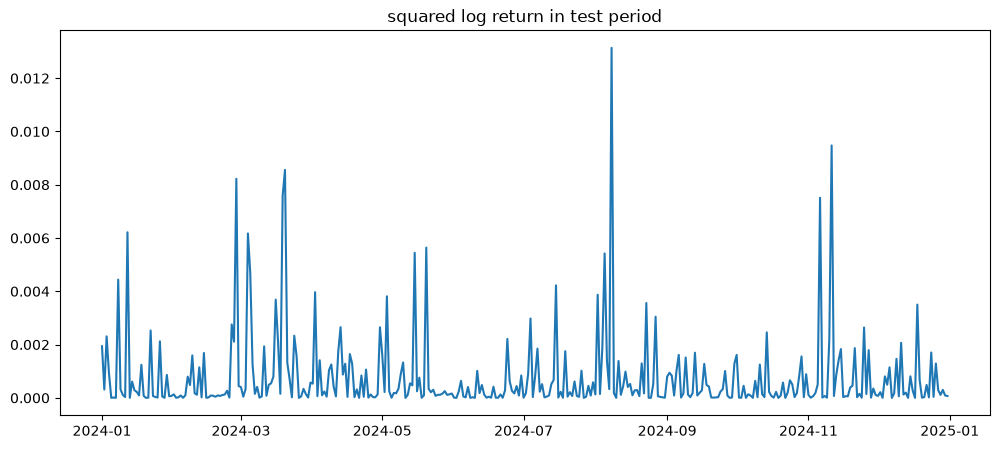

In [280]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(test["squared_log_return"])

ax.set_title("squared log return in test period")
plt.show()

The predictions that were significantly wrong were for August 8, 2024.

Looking at the graph, 0.013 was the day when the largest squared_log_return value during the test period.

This suggests that the model struggles to make accurate predictions in situations where volatility increases substantially.

Furthermore, even when the time horizon for a prediction is shortened, significant fluctuations cannot be reliably predicted.

# Summary
 
In this analysis, I used both classical statistical methods and machine learning to forecast the squared returns of Bitcoin. 

While both approaches improved prediction accuracy as measured by RMSE relative to the baseline results, they also have certain limitations.

The first point is that it is difficult for a t-GARCH model to predict large fluctuations in variance.

The second point is that, while machine learning can sometimes capture significant fluctuations in variance, it can also lead to major prediction errors.

# Model-Risk Register

| Risk | Description |
| :----------------------------: | :-------: |
| leakage risks                  | To prevent data leakage, lagged variables and moving averages are constructed using only information available at each period. In addition, model selection is based on validation performance, while test data are reserved for final evaluation. However, in this analysis, I assumed that portfolio adjustments could be made after the market closed based on forecasts of future return volatility. If, in reality, such adjustments are not possible after the close, then the current day’s data cannot be used for these forecasts. Instead, one must rely on data up to the previous day. |
| future-information assumptions | The models relies on historical relationships between observed market variables and future squared_log_return, and unexpected regulatory changes or macroeconomic shocks may change these relationships and decreases prediction accuracy.|
| robustness checks              | Both XGBoost model and Student-t GARCH model improve prediction accuracy than a naive baseline for both one day ahead and seven day ahead forecasts. When the test period is devided into a first and second half period, the RMSE in both period remain lower than that of the naive baseline. However, prediction accuarcy declined during the second half period.|
| known limitations              | Bitcoin’s volatility may shift due to regime changes, such as those involving regulations or the economic environment. It is difficult for this model to incorporate and account for such regime changes when making forecasts. In addition, forecasting performance of the models and optimal forecasting model vary across the forecast period and market conditions, |
| trigger of model retraining    | As the prediction period moves further away from the model's training period, the relationships with past values among other factors may diverge, potentially leading to a decline in performance. Therefore, the model must be retrained. Furthermore, retraining may also be necessary if there are significant changes in the broader economic condition or in regulations concerning Bitcoin trading. For example, I could implement a trigger such as retrainig the model if the RMSE of 7-day forecasts over a 30-day period turns out to be worse than that of the baseline.|